R Data Cleaning and Visualization - 2026-10-13 - Tapses1661

In [3]:
# Load required package
library(readxl)

# Load the Excel dataset
df <- read_excel("AirBnBSummary_v2.xlsx")

# Display the first few rows
head(df)

ERROR: Error: `path` does not exist: 'AirBnBSummary_v2.xlsx'


In [2]:
install.packages("readxl", repos = "https://cloud.r-project.org")

also installing the dependencies 'rematch', 'magrittr', 'pkgconfig', 'hms', 'prettyunits', 'R6', 'cellranger', 'tibble', 'cpp11', 'progress'




package 'rematch' successfully unpacked and MD5 sums checked
package 'magrittr' successfully unpacked and MD5 sums checked
package 'pkgconfig' successfully unpacked and MD5 sums checked
package 'hms' successfully unpacked and MD5 sums checked
package 'prettyunits' successfully unpacked and MD5 sums checked
package 'R6' successfully unpacked and MD5 sums checked
package 'cellranger' successfully unpacked and MD5 sums checked
package 'tibble' successfully unpacked and MD5 sums checked
package 'cpp11' successfully unpacked and MD5 sums checked
package 'progress' successfully unpacked and MD5 sums checked
package 'readxl' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Owner\AppData\Local\Temp\RtmpENwd6R\downloaded_packages


In [4]:
library(readxl)

df <- read_excel("AirBnBSummary_v2 (1).xlsx")

head(df)

id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
7909479,41706311,David,Downtown,Entire home/apt,107,30,27,365,NA
15966488,103700433,Erin,Downtown,Entire home/apt,100,1,250,74,NA
19859814,103700433,Erin,Downtown,Entire home/apt,100,1,309,79,NA
21071138,22992627,Joseph,Downtown,Entire home/apt,100,2,144,338,NA
21712505,103700433,Erin,Downtown,Entire home/apt,100,1,178,68,NA
25771375,140728885,Rick,Downtown,Entire home/apt,95,2,216,246,NA


In [5]:
# Step 1: Remove duplicate rows

cat("Duplicate rows before cleaning:\n")
duplicates_before <- df[duplicated(df), ]
print(duplicates_before)

# Remove duplicates
df_cleaned <- df[!duplicated(df), ]

cat("\nDuplicate rows after cleaning:\n")
duplicates_after <- df_cleaned[duplicated(df_cleaned), ]
print(duplicates_after)

Duplicate rows before cleaning:
# A tibble: 4 × 10
       id   host_id host_name neighbourhood  room_type      price minimum_nights
    <dbl>     <dbl> <chr>     <chr>          <chr>          <dbl>          <dbl>
1 2.73e 7 205256572 Stephanie West Olentangy Entire home/a…   296              1
2 2.86e 7 181661236 Chris     West Olentangy Entire home/a…   105              2
3 6.21e17 453019578 Devon     West Olentangy Entire home/a…    99             15
4 6.21e17 453019578 Devon     West Olentangy Entire home/a…    90             30
# ℹ 3 more variables: number_of_reviews <dbl>, availability_365 <dbl>,
#   `<StudentID>` <lgl>

Duplicate rows after cleaning:
# A tibble: 0 × 10
# ℹ 10 variables: id <dbl>, host_id <dbl>, host_name <chr>,
#   neighbourhood <chr>, room_type <chr>, price <dbl>, minimum_nights <dbl>,
#   number_of_reviews <dbl>, availability_365 <dbl>, <StudentID> <lgl>


In [6]:
# Step 2: Correct "Private room" to "Private Room"

cat("Before correction:\n")
print(table(df_cleaned$room_type))

df_cleaned$room_type[df_cleaned$room_type == "Private room"] <- "Private Room"

cat("\nAfter correction:\n")
print(table(df_cleaned$room_type))

Before correction:

Entire home/apt    Private room 
           1535             240 

After correction:

Entire home/apt    Private Room 
           1535             240 


In [7]:
# Step 3: Fill missing numeric values with the median

cat("Missing values before cleaning:\n")
print(colSums(is.na(df_cleaned)))

# Identify numeric columns
numeric_columns <- sapply(df_cleaned, is.numeric)

# Fill missing numeric values with each column's median
for (col in names(df_cleaned)[numeric_columns]) {
  df_cleaned[[col]][is.na(df_cleaned[[col]])] <- median(
    df_cleaned[[col]],
    na.rm = TRUE
  )
}

cat("\nMissing values after cleaning:\n")
print(colSums(is.na(df_cleaned)))

Missing values before cleaning:
               id           host_id         host_name     neighbourhood 
                0                 0                 0                 0 
        room_type             price    minimum_nights number_of_reviews 
                0                 4                 0                 0 
 availability_365       <StudentID> 
                5              1775 

Missing values after cleaning:
               id           host_id         host_name     neighbourhood 
                0                 0                 0                 0 
        room_type             price    minimum_nights number_of_reviews 
                0                 0                 0                 0 
 availability_365       <StudentID> 
                0              1775 


In [8]:
# Add Student ID to every row
df_cleaned$`<StudentID>` <- "Tapses1661"

cat("StudentID updated to Tapses1661\n")
print(table(df_cleaned$`<StudentID>`))

StudentID updated to Tapses1661

Tapses1661 
      1775 


In [9]:
# Step 4: Remove outliers using the IQR method

outlier_columns <- c(
  "price",
  "minimum_nights",
  "number_of_reviews",
  "availability_365"
)

cat("Rows before removing outliers:", nrow(df_cleaned), "\n")

keep_rows <- rep(TRUE, nrow(df_cleaned))

for (col in outlier_columns) {
  Q1 <- quantile(df_cleaned[[col]], 0.25, na.rm = TRUE)
  Q3 <- quantile(df_cleaned[[col]], 0.75, na.rm = TRUE)
  IQR_value <- Q3 - Q1

  lower_bound <- Q1 - 1.5 * IQR_value
  upper_bound <- Q3 + 1.5 * IQR_value

  outliers <- df_cleaned[[col]] < lower_bound |
              df_cleaned[[col]] > upper_bound

  cat(col, ":", sum(outliers), "outliers\n")

  keep_rows <- keep_rows & !outliers
}

df_cleaned <- df_cleaned[keep_rows, ]

cat("Rows after removing outliers:", nrow(df_cleaned), "\n")

Rows before removing outliers: 1775 
price : 118 outliers
minimum_nights : 296 outliers
number_of_reviews : 173 outliers
availability_365 : 0 outliers
Rows after removing outliers: 1205 


In [10]:
install.packages("writexl", repos = "https://cloud.r-project.org")

package 'writexl' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Owner\AppData\Local\Temp\RtmpENwd6R\downloaded_packages


In [11]:
# Step 5: Save the cleaned dataset

library(writexl)

output_file <- "AirBnBSummary_v2_R_Cleaned.xlsx"

write_xlsx(df_cleaned, output_file)

cat("Cleaned dataset saved successfully as:\n")
cat(output_file)

Cleaned dataset saved successfully as:
AirBnBSummary_v2_R_Cleaned.xlsx

In [12]:
# Step 6: Calculate descriptive statistics

total_count <- nrow(df_cleaned)
minimum_price <- min(df_cleaned$price)
maximum_price <- max(df_cleaned$price)
mean_price <- mean(df_cleaned$price)
median_reviews <- median(df_cleaned$number_of_reviews)

# Mode of minimum_nights
mode_minimum_nights <- as.numeric(
  names(sort(table(df_cleaned$minimum_nights), decreasing = TRUE)[1])
)

std_price <- sd(df_cleaned$price)

correlation_price_availability <- cor(
  df_cleaned$price,
  df_cleaned$availability_365
)

cat("Total count of listings:", total_count, "\n")
cat("Minimum price:", minimum_price, "\n")
cat("Maximum price:", maximum_price, "\n")
cat("Mean price of listings:", mean_price, "\n")
cat("Median number of reviews:", median_reviews, "\n")
cat("Mode of minimum_nights:", mode_minimum_nights, "\n")
cat("Standard deviation of price:", std_price, "\n")
cat("Correlation between price and availability_365:",
    correlation_price_availability, "\n")

Total count of listings: 1205 
Minimum price: 32 
Maximum price: 308 
Mean price of listings: 132.1801 
Median number of reviews: 20 
Mode of minimum_nights: 1 
Standard deviation of price: 62.53379 
Correlation between price and availability_365: 0.09281346 


In [13]:
# Step 6: Calculate descriptive statistics

total_count <- nrow(df_cleaned)
minimum_price <- min(df_cleaned$price)
maximum_price <- max(df_cleaned$price)
mean_price <- mean(df_cleaned$price)
median_reviews <- median(df_cleaned$number_of_reviews)

# Mode of minimum_nights
mode_minimum_nights <- as.numeric(
  names(sort(table(df_cleaned$minimum_nights), decreasing = TRUE)[1])
)

std_price <- sd(df_cleaned$price)

correlation_price_availability <- cor(
  df_cleaned$price,
  df_cleaned$availability_365
)

cat("Total count of listings:", total_count, "\n")
cat("Minimum price:", minimum_price, "\n")
cat("Maximum price:", maximum_price, "\n")
cat("Mean price of listings:", mean_price, "\n")
cat("Median number of reviews:", median_reviews, "\n")
cat("Mode of minimum_nights:", mode_minimum_nights, "\n")
cat("Standard deviation of price:", std_price, "\n")
cat("Correlation between price and availability_365:",
    correlation_price_availability, "\n")

Total count of listings: 1205 
Minimum price: 32 
Maximum price: 308 
Mean price of listings: 132.1801 
Median number of reviews: 20 
Mode of minimum_nights: 1 
Standard deviation of price: 62.53379 
Correlation between price and availability_365: 0.09281346 


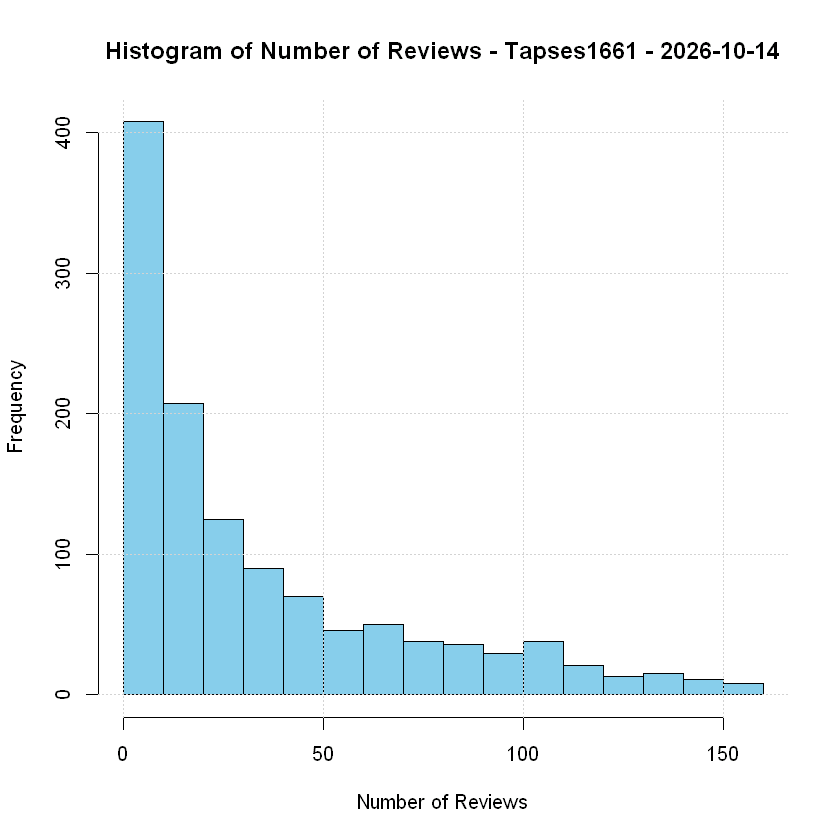

In [14]:
# Step 7: Histogram of number_of_reviews

hist(
  df_cleaned$number_of_reviews,
  breaks = 20,
  main = "Histogram of Number of Reviews - Tapses1661 - 2026-10-14",
  xlab = "Number of Reviews",
  ylab = "Frequency",
  col = "skyblue",
  border = "black"
)

grid()

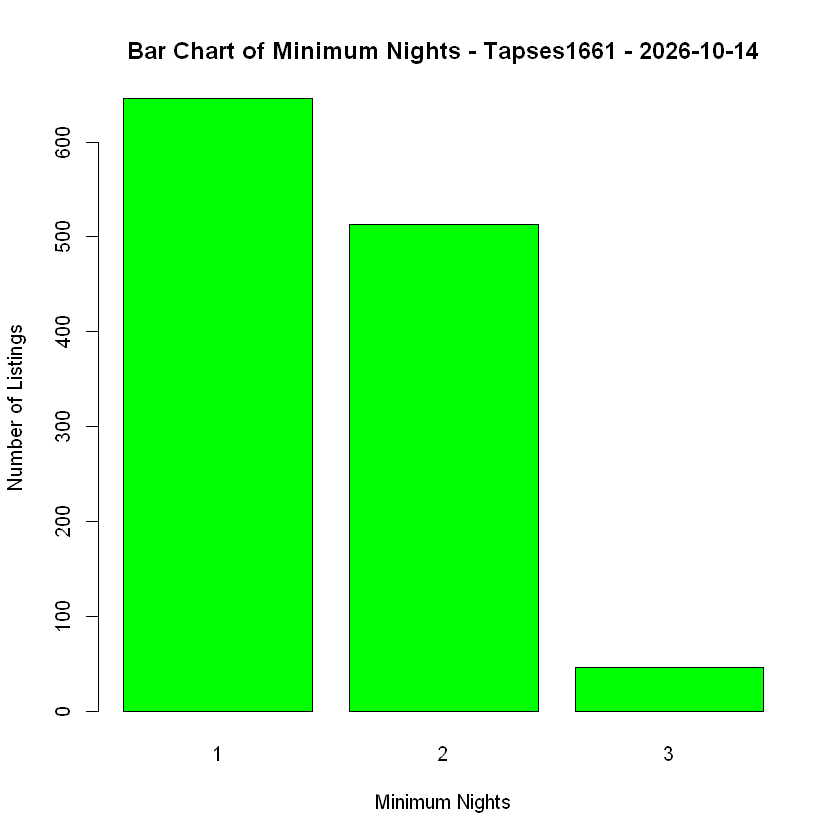

In [15]:
# Step 8: Bar chart of minimum_nights

minimum_nights_counts <- table(df_cleaned$minimum_nights)

barplot(
  minimum_nights_counts,
  main = "Bar Chart of Minimum Nights - Tapses1661 - 2026-10-14",
  xlab = "Minimum Nights",
  ylab = "Number of Listings",
  col = "green"
)

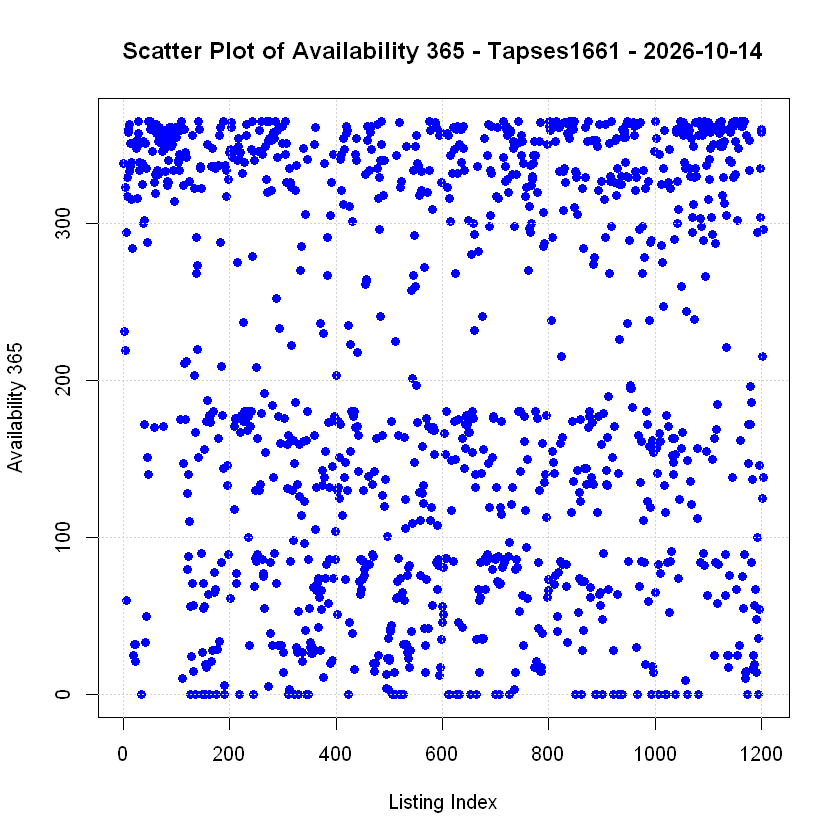

In [16]:
# Step 9: Scatter plot of availability_365

plot(
  df_cleaned$availability_365,
  main = "Scatter Plot of Availability 365 - Tapses1661 - 2026-10-14",
  xlab = "Listing Index",
  ylab = "Availability 365",
  pch = 19,
  col = "blue"
)

grid()

In [17]:
# Step 10: Correlation heat map

library(corrplot)

correlation_columns <- c(
  "price",
  "minimum_nights",
  "number_of_reviews",
  "availability_365"
)

correlation_matrix <- cor(
  df_cleaned[correlation_columns],
  use = "complete.obs"
)

corrplot(
  correlation_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.cex = 0.8,
  title = "Correlation Heat Map - Tapses1661 - 2026-10-14",
  mar = c(0, 0, 2, 0)
)

ERROR: Error in library(corrplot): there is no package called 'corrplot'


In [18]:
install.packages("corrplot", repos = "https://cloud.r-project.org")

package 'corrplot' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Owner\AppData\Local\Temp\RtmpENwd6R\downloaded_packages


corrplot 0.95 loaded



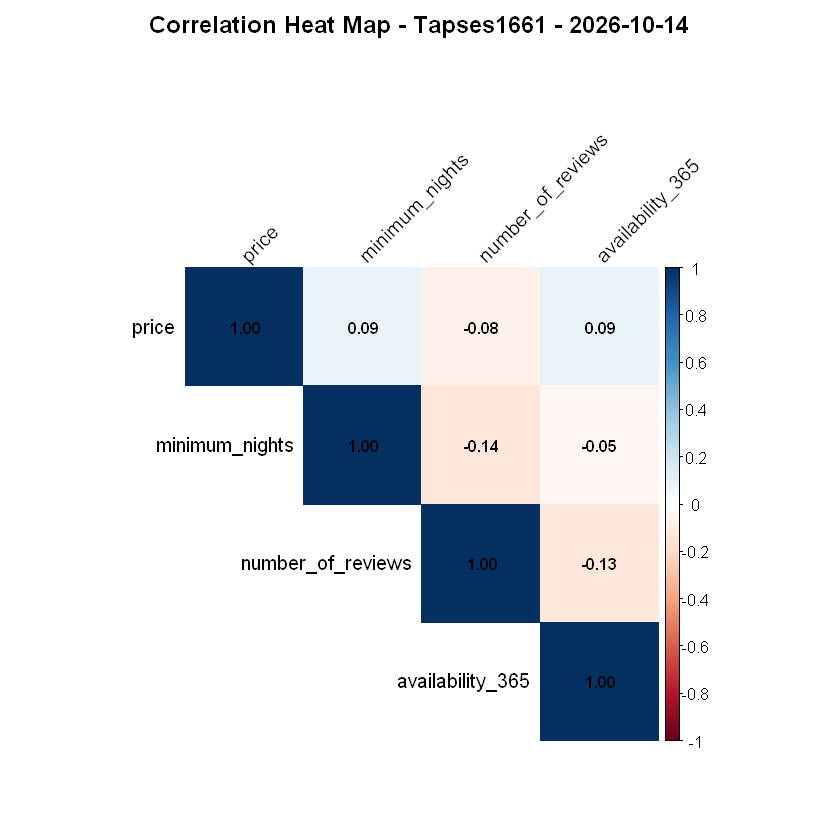

In [19]:
library(corrplot)

correlation_columns <- c(
  "price",
  "minimum_nights",
  "number_of_reviews",
  "availability_365"
)

correlation_matrix <- cor(
  df_cleaned[correlation_columns],
  use = "complete.obs"
)

corrplot(
  correlation_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.cex = 0.8,
  title = "Correlation Heat Map - Tapses1661 - 2026-10-14",
  mar = c(0, 0, 2, 0)
)